In [42]:
import xgboost as xgb
import shap
import csv
import pandas as pd
import json
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

In [43]:
shap.initjs()
# 使用一个可用的数据集
# X, y = shap.datasets.adult()
# y = (y == '>50K')  # 转换为二元分类问题
df = pd.read_csv("record.csv",sep=",")
# 假设目标变量在最后一列
X = df.iloc[:, :-1]  # 特征
y = df.iloc[:, -1]   # 目标变量

In [44]:
# 分割数据为训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# 训练随机森林回归模型
model = RandomForestRegressor(n_estimators=100, random_state=42)
# 训练模型
model.fit(X, y)

# 使用SHAP解释模型
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X)


In [48]:
# 可视化第一个预测的解释
shap.initjs()
shap.force_plot(explainer.expected_value, shap_values[0,:], X.iloc[213,:])

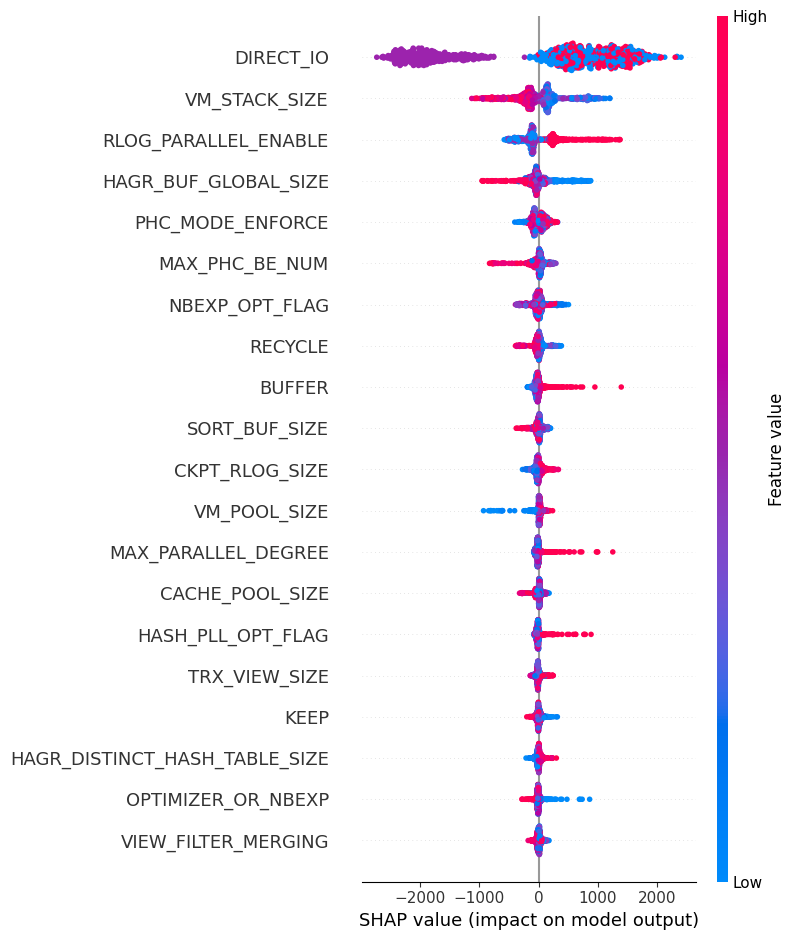

In [46]:
shap.summary_plot(shap_values, X)